# Campaign Finance: descriptive charts

Ohio Senate, 2026. Principal campaign committees only: Brown C00916288 and Husted C00896019.
Version 2 implements the student's chosen inflow measure: total receipts less contribution refunds.
Transfers are already included in total receipts and are not added a second time.
Both financial-flow bars and quarter-end cash cover 2026 Q1–Q3;
the Q3 summary also retains September 30 cash and debts.
Source: FEC processed reports collected October 18, 2026, financial clean v2.

Run all code cells from the course directory, notebook directory, or a downloaded group folder.
In the shared group layout, files live under `clean/campaign_finance/`,
`notebooks/campaign_finance/`, and `output/campaign_finance/`.
The earlier flat group layout remains supported. Python 3 and matplotlib are required.
All code is marked as developed with assistance from ChatGPT. This notebook supplies data,
definitions and descriptive plots; the student's graded interpretation and prediction are not drafted.


In [1]:
# Author: Jingyang
# code developed with assistance from ChatGPT
import csv
import hashlib
from datetime import date, timedelta
from decimal import Decimal
from pathlib import Path
import matplotlib.pyplot as plt

filename = "finance_snapshot_20260930_v2.csv"
expected_sha256 = "10666904D8C0E2AB474A2143BAD74B177ADD470C32C6B0D29A6B3D0A59D8E298"
locations = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    for project in [parent, parent / "05-election-project"]:
        locations.append((project / "02-data/processed/campaign-finance" / filename,
                          project / "03-code-and-models/campaign-finance/output"))
    locations.append((parent / "clean/campaign_finance" / filename,
                      parent / "output/campaign_finance"))
    locations.append((parent / "clean" / filename, parent / "output"))
input_path, output_dir = next((source, target) for source, target in locations if source.is_file())
assert hashlib.sha256(input_path.read_bytes()).hexdigest().upper() == expected_sha256, "Input version changed"
with input_path.open(encoding="utf-8-sig", newline="") as stream:
    all_rows = list(csv.DictReader(stream))
reports_path = input_path.with_name("finance_reports_clean_v2.csv")
assert hashlib.sha256(reports_path.read_bytes()).hexdigest().upper() == "AA493856A52F6ED5324D1F17FDC01558100B23FECCAC0F3AA2BC6336C8499702", "Report history version changed"
with reports_path.open(encoding="utf-8-sig", newline="") as stream:
    report_history = list(csv.DictReader(stream))
committees = [("Brown", "C00916288"), ("Husted", "C00896019")]
rows = []
for label, committee_id in committees:
    matches = [row for row in all_rows if row["committee_id"] == committee_id]
    assert len(matches) == 1
    row = matches[0]
    assert row["coverage_start_date"] == "2026-07-01" and row["coverage_end_date"] == "2026-09-30"
    assert row["currency"] == "USD"
    rows.append(row)
output_dir.mkdir(parents=True, exist_ok=True)
colors = ["#2864A6", "#C44747"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 14,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Inputs: financial snapshot and report history v2; principal campaign committees only.")


Inputs: financial snapshot and report history v2; principal campaign committees only.


## Summary table

USD amounts come from financial clean v2. Receipts after contribution refunds are a transparent
derived analysis measure, not an official FEC field called net contributions. Operating offsets
remain in receipts as reported; net operating expenditures also deduct those offsets. Therefore
the two displayed columns must not be subtracted to infer cash flow. The original total receipts
and disbursements remain available for the cash identity.
Candidate contributions and Q3 loan receipts/repayments are zero for these two committees.
Other committees and independent expenditures are outside these charts.


In [2]:
# code developed with assistance from ChatGPT
fields = ["receipts_less_contribution_refunds", "net_operating_expenditures_period",
          "cash_on_hand_end_period", "debts_owed_by_committee"]
summary = []
source_details = []
receipt_category_values = []
contributor_values = []
classification_rows = []
for (label, committee_id), row in zip(committees, rows):
    D = lambda key: Decimal(row[key])
    assert D("net_contributions_period") == D("total_contributions_period") - D("total_contribution_refunds_period")
    assert D("net_operating_expenditures_period") == D("operating_expenditures_period") - D("offsets_to_operating_expenditures_period")
    assert D("cash_on_hand_beginning_period") + D("total_receipts_period") - D("total_disbursements_period") == D("cash_on_hand_end_period")
    assert all(D(key) == 0 for key in ["candidate_contribution_period", "total_loans_received_period", "total_loan_repayments_period"])
    row["receipts_less_contribution_refunds"] = format(D("total_receipts_period") - D("total_contribution_refunds_period"), ".2f")
    assert D("total_contribution_refunds_period") == sum(D(key) for key in [
        "refunded_individual_contributions_period", "refunded_other_political_committee_contributions_period",
        "refunded_political_party_committee_contributions_period"])
    components = [
        ("Individual contributions", D("total_individual_contributions_period"), D("refunded_individual_contributions_period")),
        ("Other political committee contributions", D("other_political_committee_contributions_period"), D("refunded_other_political_committee_contributions_period")),
        ("Political party contributions", D("political_party_committee_contributions_period"), D("refunded_political_party_committee_contributions_period")),
        ("Reported candidate contributions", D("candidate_contribution_period"), Decimal(0)),
        ("Transfers from other authorized committees", D("transfers_from_other_authorized_committee_period"), Decimal(0)),
        ("Loans received", D("total_loans_received_period"), Decimal(0)),
        ("Other receipts", D("other_receipts_period"), Decimal(0)),
        ("Operating offsets", D("offsets_to_operating_expenditures_period"), Decimal(0))]
    amounts = [gross - refunds for category, gross, refunds in components]
    assert sum(amounts) == D("receipts_less_contribution_refunds")
    receipt_parts = [D("net_contributions_period"), amounts[4], sum(amounts[i] for i in [5, 6, 7])]
    contributor_parts = amounts[:4]
    assert sum(receipt_parts) == D("receipts_less_contribution_refunds")
    assert sum(contributor_parts) == D("net_contributions_period")
    receipt_category_values.append(receipt_parts)
    contributor_values.append(contributor_parts)
    for level, labels, parts, denominator in [
        ("Receipt accounting category", ["Net contributions", "Transfers", "Other receipts and operating offsets"], receipt_parts, D("receipts_less_contribution_refunds")),
        ("Reported contributor category", ["Individuals", "Other political committees", "Party committees", "Reported candidate contributions"], contributor_parts, D("net_contributions_period"))]:
        for category, amount in zip(labels, parts):
            classification_rows.append({"candidate": label, "committee_id": committee_id,
                "period_start": "2026-07-01", "period_end": "2026-09-30", "currency": "USD",
                "classification_level": level, "category": category, "amount": format(amount, ".2f"),
                "denominator": format(denominator, ".2f"), "share_percent": format(amount / denominator * 100, ".4f")})
    for (category, gross, refunds), amount in zip(components, amounts):
        source_details.append({"candidate": label, "committee_id": committee_id, "period_start": "2026-07-01",
            "period_end": "2026-09-30", "currency": "USD", "source_category": category,
            "gross_amount": format(gross, ".2f"), "contribution_refunds": format(refunds, ".2f"),
            "amount_after_contribution_refunds": format(amount, ".2f"),
            "share_percent": format(amount / D("receipts_less_contribution_refunds") * 100, ".4f")})
    summary.append({"candidate": label, "committee_id": committee_id,
                    "period_start": row["coverage_start_date"], "period_end": row["coverage_end_date"],
                    "currency": "USD", **{key: row[key] for key in fields}})
summary_path = output_dir / "funding_summary_v2.csv"
with summary_path.open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)
sources_path = output_dir / "receipt_sources_v2.csv"
with sources_path.open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(source_details[0]))
    writer.writeheader()
    writer.writerows(source_details)
classification_path = output_dir / "classification_v3.csv"
with classification_path.open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(classification_rows[0]))
    writer.writeheader()
    writer.writerows(classification_rows)
print("Candidate | Receipts less contribution refunds | Net operating expenditures | Cash on hand | Debt")
for item in summary:
    print(item["candidate"] + " | " + " | ".join(f"${Decimal(item[key]):,.2f}" for key in fields))


Candidate | Receipts less contribution refunds | Net operating expenditures | Cash on hand | Debt
Brown | $22,736,238.26 | $34,101,093.21 | $4,861,451.93 | $0.00
Husted | $4,718,137.01 | $5,252,461.08 | $8,883,293.28 | $0.00


## Table 2: Receipt accounting categories

This view groups reported receipt types, not ultimate donors. Net contributions, transfers,
and other receipts/operating offsets are kept at the accounting-category level. Loans are zero
for both committees in this period. The accompanying detailed receipt CSV retains all FEC components.


In [3]:
# code developed with assistance from ChatGPT
print("Receipt accounting category | Brown USD | Husted USD")
for index, category in enumerate(["Net contributions", "Transfers", "Other receipts and operating offsets"]):
    print(category + " | " + " | ".join(f"${parts[index]:,.2f}" for parts in receipt_category_values))
print("These reported receipt categories do not identify ultimate donors behind transfers.")


Receipt accounting category | Brown USD | Husted USD
Net contributions | $20,253,844.15 | $3,252,897.07
Transfers | $2,409,185.51 | $1,464,038.84
Other receipts and operating offsets | $73,208.60 | $1,201.10
These reported receipt categories do not identify ultimate donors behind transfers.


## Table 3: Contributor categories within reported contributions

The denominator is net contributions only; transfers are excluded. Individual, political-party,
and other political-committee categories are reduced by their corresponding refund buckets.
Reported candidate contributions are zero. This view cannot classify the donors behind transfers
or describe the composition of all campaign funding. Individuals are not synonymous with small donors.


In [4]:
# code developed with assistance from ChatGPT
with classification_path.open(encoding="utf-8-sig", newline="") as stream:
    contribution_table = [item for item in csv.DictReader(stream)
                          if item["classification_level"] == "Reported contributor category"]
print("Reported category | Brown USD (share) | Husted USD (share)")
for category in ["Individuals", "Other political committees", "Party committees", "Reported candidate contributions"]:
    parts = [next(item for item in contribution_table if item["candidate"] == label
                  and item["category"] == category) for label, committee_id in committees]
    print(category + " | " + " | ".join(f"${Decimal(item['amount']):,.2f} ({Decimal(item['share_percent']):.4f}%)"
                                          for item in parts))
print("Denominator: reported net contributions only. Transfers are outside this table.")


Reported category | Brown USD (share) | Husted USD (share)
Individuals | $20,087,522.00 (99.1788%) | $2,887,147.07 (88.7562%)
Other political committees | $166,322.15 (0.8212%) | $362,350.00 (11.1393%)
Party committees | $0.00 (0.0000%) | $3,400.00 (0.1045%)
Reported candidate contributions | $0.00 (0.0000%) | $0.00 (0.0000%)
Denominator: reported net contributions only. Transfers are outside this table.


## Quarterly comparison table

Q1 covers January–March, Q2 April–June, and Q3 July–September 2026. Q2 combines the
April 1–15 pre-primary report and April 16–June 30 report. Flow amounts are summed over
non-overlapping, consecutive reports. Cash is taken from the final report of each quarter.
The source coverage and cash identity are checked before this six-row table is saved.
Receipts after contribution refunds and net operating expenditures are descriptive measures;
their difference is not cash flow because operating offsets enter both measures.


In [5]:
# code developed with assistance from ChatGPT
quarterly = []
quarters = [("Q1", "2026-01-01", "2026-03-31"),
            ("Q2", "2026-04-01", "2026-06-30"),
            ("Q3", "2026-07-01", "2026-09-30")]
flow_fields = ["total_receipts_period", "total_disbursements_period",
               "total_contribution_refunds_period", "net_contributions_period",
               "net_operating_expenditures_period", "offsets_to_operating_expenditures_period"]
for label, committee_id in committees:
    for quarter, start, end in quarters:
        selected = sorted([item for item in report_history if item["committee_id"] == committee_id
                           and start <= item["coverage_start_date"] and item["coverage_end_date"] <= end],
                          key=lambda item: item["coverage_start_date"])
        assert selected and selected[0]["coverage_start_date"] == start
        assert selected[-1]["coverage_end_date"] == end
        if quarter == "Q2":
            assert [item["report_type"] for item in selected] == ["12P", "Q2"]
        for item in selected:
            assert item["currency"] == "USD"
            assert Decimal(item["cash_on_hand_beginning_period"]) + Decimal(item["total_receipts_period"]) - Decimal(item["total_disbursements_period"]) == Decimal(item["cash_on_hand_end_period"])
        for previous, item in zip(selected, selected[1:]):
            assert date.fromisoformat(previous["coverage_end_date"]) + timedelta(days=1) == date.fromisoformat(item["coverage_start_date"])
            assert Decimal(previous["cash_on_hand_end_period"]) == Decimal(item["cash_on_hand_beginning_period"])
        totals = {key: sum((Decimal(item[key]) for item in selected), Decimal(0)) for key in flow_fields}
        beginning = Decimal(selected[0]["cash_on_hand_beginning_period"])
        ending = Decimal(selected[-1]["cash_on_hand_end_period"])
        if quarter != "Q1":
            assert quarterly[-1]["candidate"] == label
            assert Decimal(quarterly[-1]["cash_on_hand_end_period"]) == beginning
        assert beginning + totals["total_receipts_period"] - totals["total_disbursements_period"] == ending
        quarterly.append({"candidate": label, "committee_id": committee_id, "quarter": quarter,
            "period_start": start, "period_end": end, "currency": "USD",
            "source_file_numbers": ";".join(item["file_number"] for item in selected),
            "source_report_count": len(selected), **{key: format(value, ".2f") for key, value in totals.items()},
            "receipts_less_contribution_refunds": format(totals["total_receipts_period"] - totals["total_contribution_refunds_period"], ".2f"),
            "cash_on_hand_beginning_period": format(beginning, ".2f"),
            "cash_on_hand_end_period": format(ending, ".2f"),
            "debts_owed_by_committee": selected[-1]["debts_owed_by_committee"]})
assert len(quarterly) == 6
quarterly_path = output_dir / "quarterly_principal_2026_v1.csv"
with quarterly_path.open("w", encoding="utf-8-sig", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(quarterly[0]))
    writer.writeheader()
    writer.writerows(quarterly)
print("Candidate | Quarter | Receipts after refunds | Net operating expenditures | Closing cash")
for item in quarterly:
    print(item["candidate"] + " | " + item["quarter"] + " | " + " | ".join(
        f"${Decimal(item[key]):,.2f}" for key in ["receipts_less_contribution_refunds",
            "net_operating_expenditures_period", "cash_on_hand_end_period"]))


Candidate | Quarter | Receipts after refunds | Net operating expenditures | Closing cash
Brown | Q1 | $10,069,075.72 | $3,452,700.74 | $16,514,461.43
Brown | Q2 | $13,971,357.69 | $14,255,658.85 | $16,229,741.32
Brown | Q3 | $22,736,238.26 | $34,101,093.21 | $4,861,451.93
Husted | Q1 | $2,859,954.52 | $578,551.73 | $8,239,954.70
Husted | Q2 | $3,977,889.76 | $2,791,805.16 | $9,418,818.45
Husted | Q3 | $4,718,137.01 | $5,252,461.08 | $8,883,293.28


## Chart 1: Quarterly financial flows

Q1–Q3 receipts after contribution refunds and net operating expenditures, with narrow bars.
Transfers remain included. Differences between the bars are not cash change.


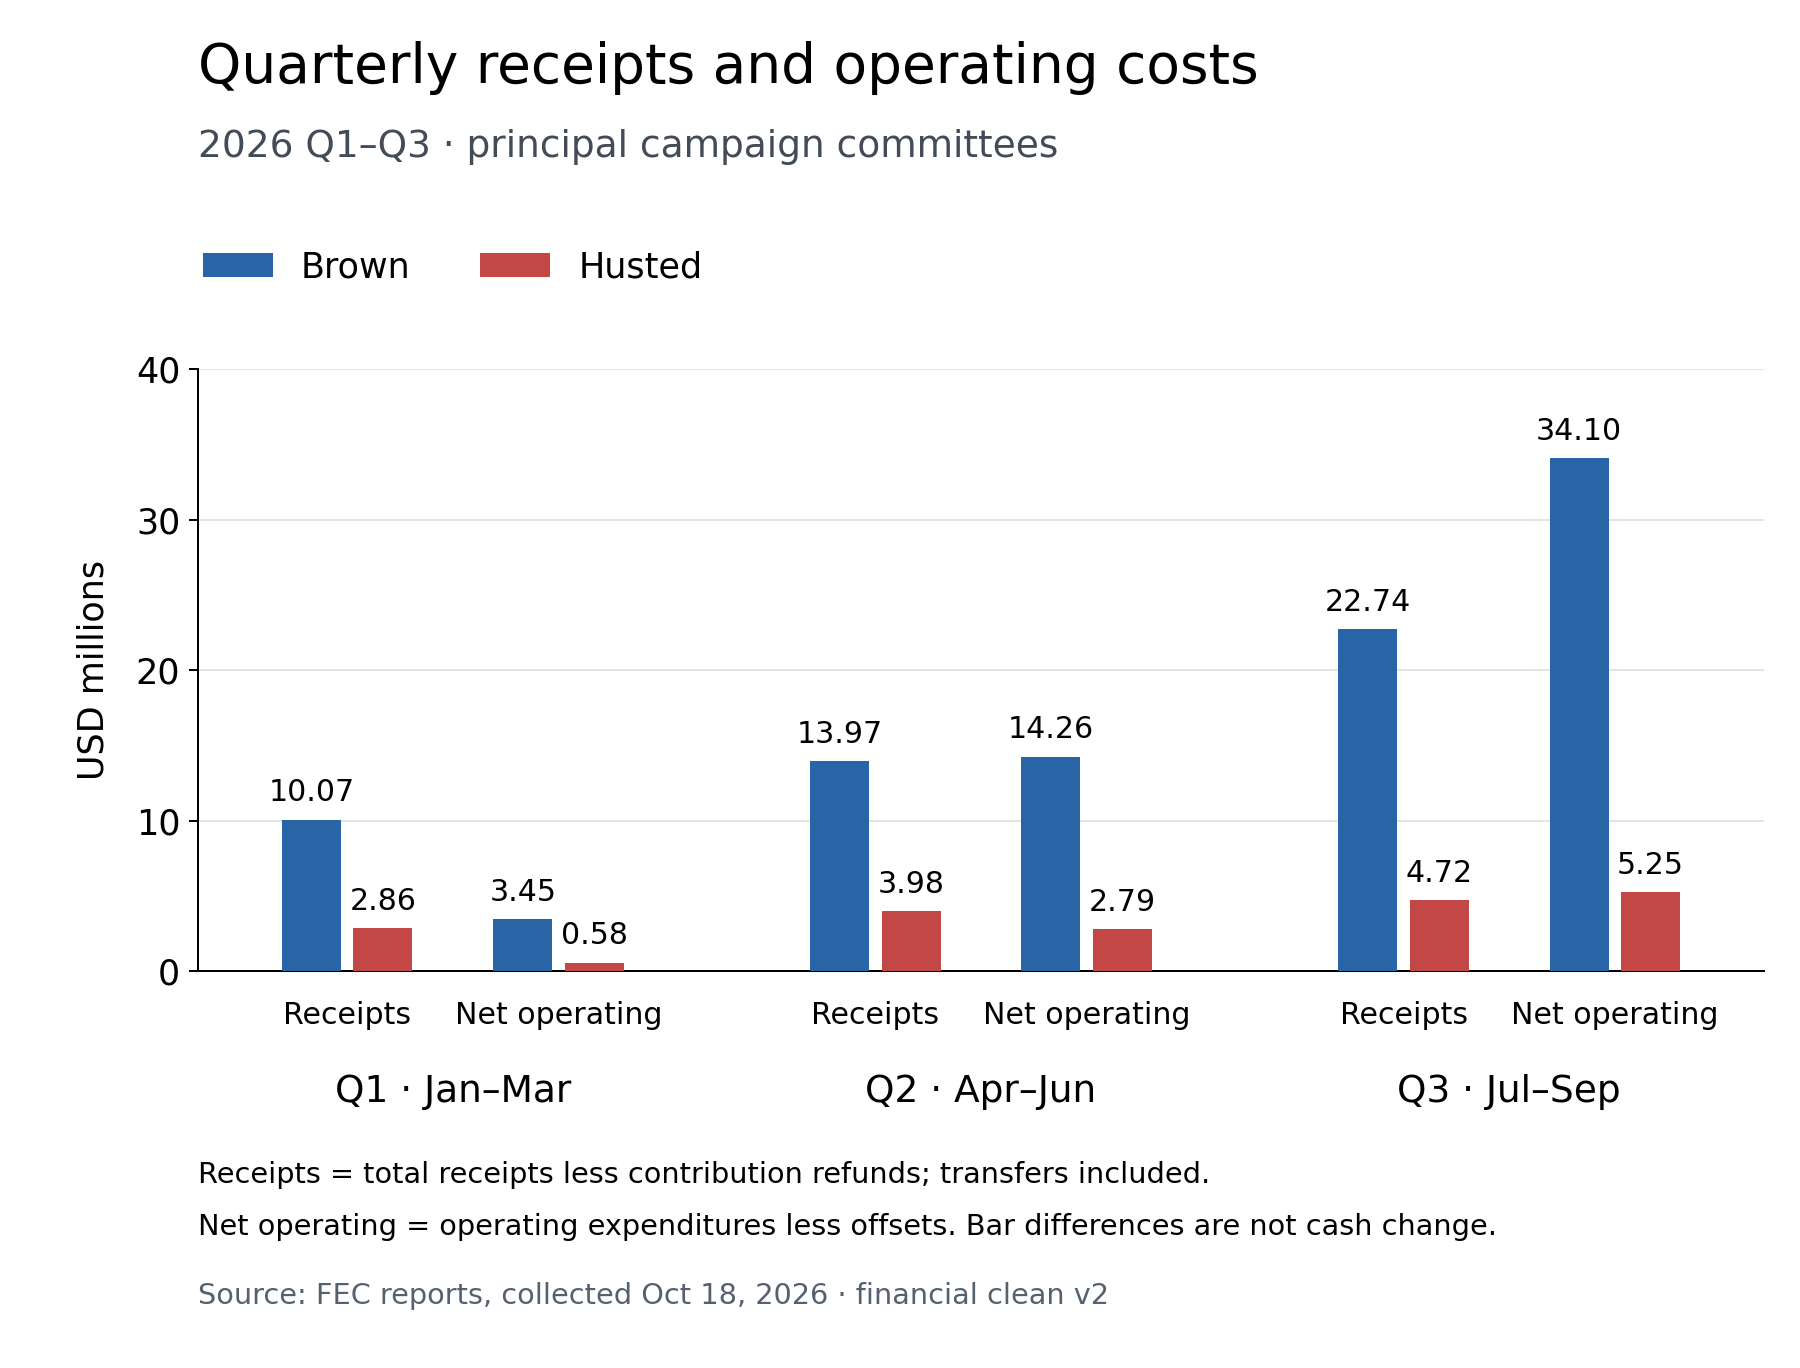

In [6]:
# code developed with assistance from ChatGPT
data={(r["candidate"],r["quarter"]):r for r in quarterly}
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":14,"axes.spines.top":False,"axes.spines.right":False})
fig,ax=plt.subplots(figsize=(10,7.6),dpi=180)
fig.subplots_adjust(left=.11,right=.98,bottom=.29,top=.73)
fig.suptitle("Quarterly receipts and operating costs",fontsize=22,x=.11,y=.97,ha="left")
fig.text(.11,.885,"2026 Q1–Q3 · principal campaign committees",fontsize=15,color="#424B57")
centers=[0,1.7,3.4]
fields=["receipts_less_contribution_refunds","net_operating_expenditures_period"]
positions=[]
labels=[]
for q,center in zip(["Q1","Q2","Q3"],centers):
    for j,field in enumerate(fields):
        x=center+(-.34 if j==0 else .34)
        positions.append(x)
        labels.append("Receipts" if j==0 else "Net operating")
        for k,(name,color) in enumerate([("Brown","#2864A6"),("Husted","#C44747")]):
            r=data[(name,q)]
            value=float(Decimal(r[field])/Decimal(1000000))
            assert value>=0
            bar=ax.bar(x+(k-.5)*.23,value,width=.19,color=color,zorder=3,label=name if q=="Q1" and j==0 else None)
            ax.bar_label(bar,labels=[f"{value:.2f}"],padding=5,fontsize=12)
for center,q,months in zip(centers,["Q1","Q2","Q3"],["Jan–Mar","Apr–Jun","Jul–Sep"]):
    ax.text(center,-.17,q+" · "+months,transform=ax.get_xaxis_transform(),ha="center",va="top",fontsize=15)
ax.set_xticks(positions,labels)
ax.tick_params(axis="x",length=0,pad=12,labelsize=12)
ax.set_xlim(-.82,4.22)
ax.set_ylim(0,40)
ax.set_yticks([0,10,20,30,40])
ax.set_ylabel("USD millions",labelpad=10)
ax.grid(axis="y",color="#E0E5EC",linewidth=.8,zorder=0)
fig.legend(*ax.get_legend_handles_labels(),loc="upper left",bbox_to_anchor=(.095,.84),ncol=2,frameon=False,fontsize=14)
fig.text(.11,.135,"Receipts = total receipts less contribution refunds; transfers included.",fontsize=11.5)
fig.text(.11,.097,"Net operating = operating expenditures less offsets. Bar differences are not cash change.",fontsize=11.5)
fig.text(.11,.047,"Source: FEC reports, collected Oct 18, 2026 · financial clean v2",fontsize=11.5,color="#556070")
fig.savefig(output_dir / "quarterly_receipts_and_costs_v1.png",dpi=180,facecolor="white")
plt.show()


## Chart 2: Quarter-end cash

The vertical axis is USD millions and starts at zero. Each point is the closing cash balance
on March 31, June 30, or September 30, 2026. Connecting lines only help compare quarter ends;
they do not estimate the unobserved monthly path. Period loans are not subtracted from actual cash.
These reported balances do not identify spending effectiveness or imply election probabilities.


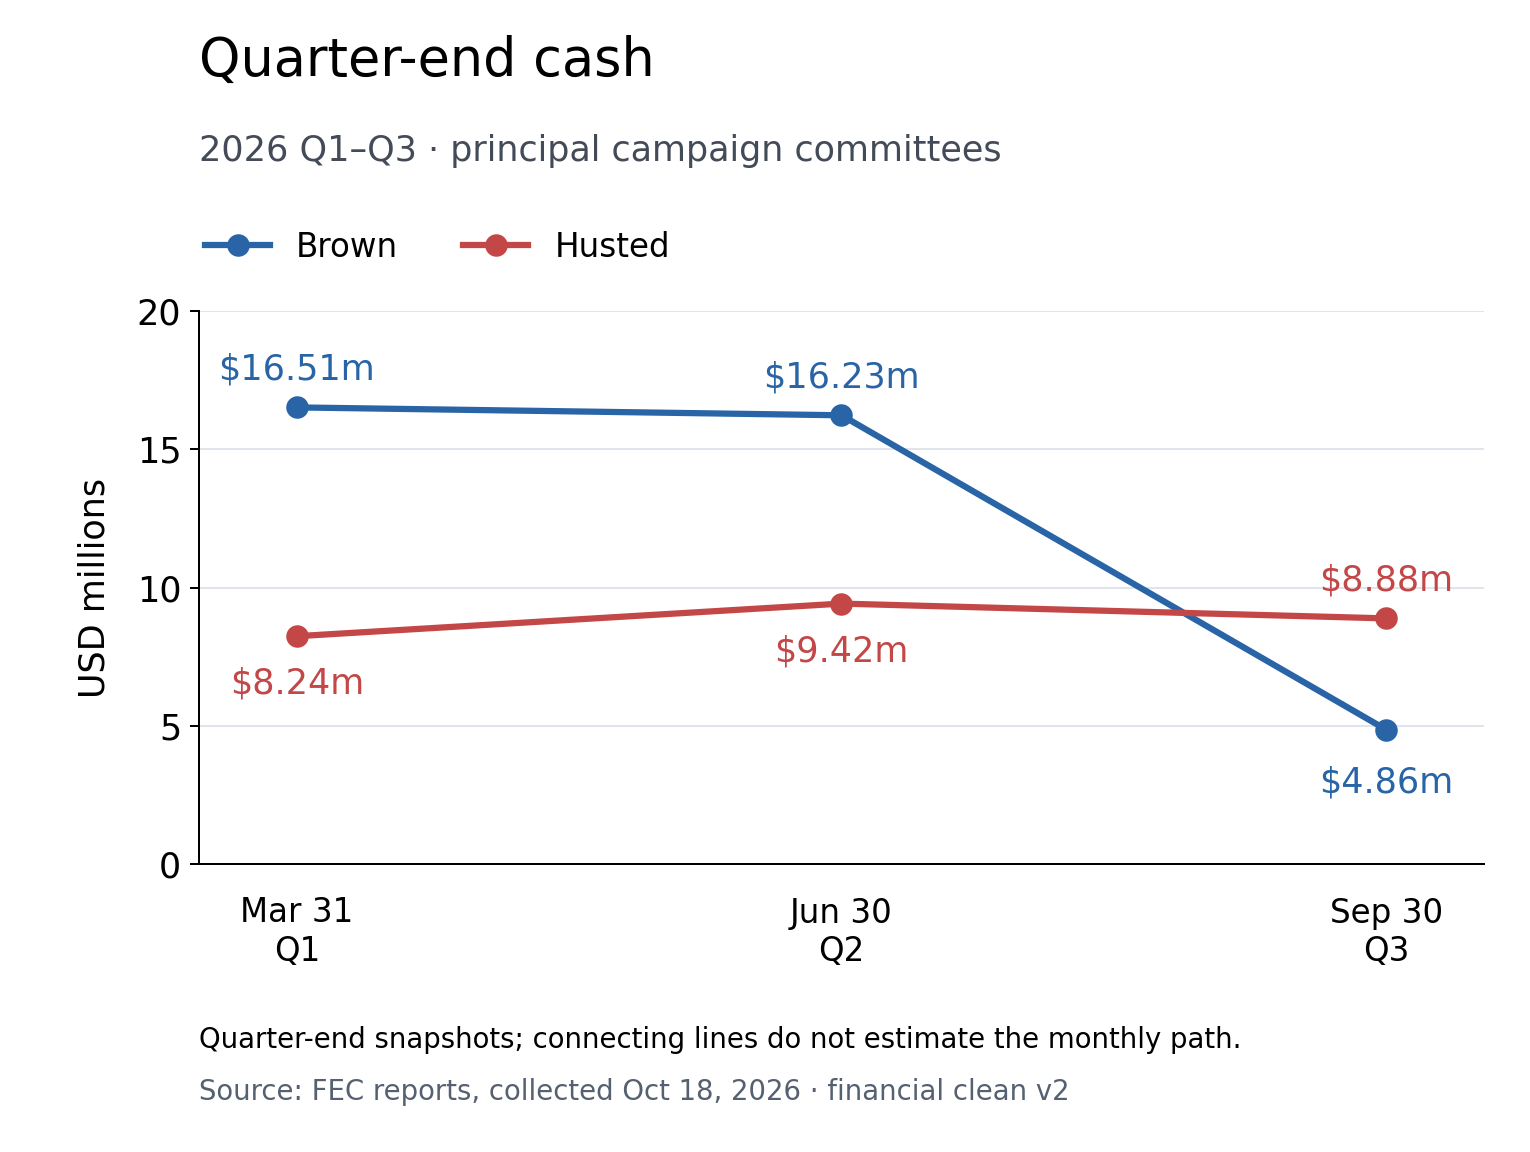

In [7]:
# code developed with assistance from ChatGPT
fig, ax = plt.subplots(figsize=(8.5, 6.4), dpi=180)
fig.subplots_adjust(left=.13, right=.97, bottom=.25, top=.73)
fig.suptitle("Quarter-end cash", fontsize=21, x=.13, y=.97, ha="left")
fig.text(.13, .86, "2026 Q1–Q3 · principal campaign committees", fontsize=14, color="#424B57")
for index, (label, committee_id) in enumerate(committees):
    cash = [float(Decimal(next(item for item in quarterly if item["candidate"] == label
                              and item["quarter"] == quarter)["cash_on_hand_end_period"]) / Decimal(1000000))
            for quarter, start, end in quarters]
    ax.plot([0, 1, 2], cash, marker="o", markersize=8, linewidth=2.5,
            color=colors[index], label=label, zorder=3)
    for position, value in enumerate(cash):
        offset = (11 if position < 2 else -25) if index == 0 else (-23 if position < 2 else 11)
        ax.annotate(f"${value:.2f}m", (position, value), xytext=(0, offset),
                    textcoords="offset points", ha="center", fontsize=14, color=colors[index])
ax.set_xticks([0, 1, 2], ["Mar 31\nQ1", "Jun 30\nQ2", "Sep 30\nQ3"])
ax.set_xlim(-.18, 2.18)
ax.tick_params(axis="x", length=0, pad=13, labelsize=13)
ax.set_ylabel("USD millions", labelpad=10)
ax.set_ylim(0, 20)
ax.set_yticks([0, 5, 10, 15, 20])
ax.grid(axis="y", color="#E0E5EC", linewidth=.8, zorder=0)
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(.115, .825),
           ncol=2, frameon=False, fontsize=13)
fig.text(.13, .09, "Quarter-end snapshots; connecting lines do not estimate the monthly path.", fontsize=11)
fig.text(.13, .045, "Source: FEC reports, collected Oct 18, 2026 · financial clean v2", fontsize=11, color="#556070")
fig.savefig(output_dir / "cash_trend_2026_v1.png", dpi=180, facecolor="white")
plt.show()
